# Robotics 34753 – Project (corrected)
Changes vs. the previous version:
- New `task_jac` helper: the orientation row is now `sin(q1)*w_x - cos(q1)*w_y` (z-component of x-dot of the stylus), used in Problems 5, 6, 7, 8
- Problem 5 sets `j = 9` explicitly (no stale `qj`)
- Problem 9 plotted against phi, unit N·mm, legend fixed
- Problem 10: `I0` without the parallel-axis double count, converted to SI
- Plots are saved to `figures/`

In [31]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sympy import *
os.makedirs("figures", exist_ok=True)

## Problem 1 – Direct kinematics

In [32]:
theta, alpha, d, a = symbols("theta alpha d a")
Ai = Matrix([
    [cos(theta), -sin(theta)*cos(alpha),  sin(theta)*sin(alpha), a*cos(theta)],
    [sin(theta),  cos(theta)*cos(alpha), -cos(theta)*sin(alpha), a*sin(theta)],
    [0,           sin(alpha),             cos(alpha),            d],
    [0, 0, 0, 1]])
t1, t2, t3, t4 = symbols("theta_1 theta_2 theta_3 theta_4")

A01 = Ai.subs({theta: t1,        d: 50, a: 0,  alpha: pi/2})
A12 = Ai.subs({theta: t2 + pi/2, d: 0,  a: 93, alpha: 0})
A23 = Ai.subs({theta: t3,        d: 0,  a: 93, alpha: 0})
A34 = Ai.subs({theta: t4,        d: 0,  a: 50, alpha: 0})

T01 = A01
T02 = T01*A12
T03 = T02*A23
T04 = simplify(T03*A34)

# camera frame {5}: -15 mm along x4, +45 mm along y4
A45 = Matrix([[1,0,0,-15],[0,1,0,45],[0,0,1,0],[0,0,0,1]])
T05 = simplify(T04*A45)
T04

Matrix([
[-sin(theta_2 + theta_3 + theta_4)*cos(theta_1), -cos(theta_1)*cos(theta_2 + theta_3 + theta_4),  sin(theta_1), -(93*sin(theta_2) + 93*sin(theta_2 + theta_3) + 50*sin(theta_2 + theta_3 + theta_4))*cos(theta_1)],
[-sin(theta_1)*sin(theta_2 + theta_3 + theta_4), -sin(theta_1)*cos(theta_2 + theta_3 + theta_4), -cos(theta_1), -(93*sin(theta_2) + 93*sin(theta_2 + theta_3) + 50*sin(theta_2 + theta_3 + theta_4))*sin(theta_1)],
[              cos(theta_2 + theta_3 + theta_4),              -sin(theta_2 + theta_3 + theta_4),             0,            93*cos(theta_2) + 93*cos(theta_2 + theta_3) + 50*cos(theta_2 + theta_3 + theta_4) + 50],
[                                             0,                                              0,             0,                                                                                                 1]])

In [33]:
T05

Matrix([
[-sin(theta_2 + theta_3 + theta_4)*cos(theta_1), -cos(theta_1)*cos(theta_2 + theta_3 + theta_4),  sin(theta_1), -(93*sin(theta_2) + 93*sin(theta_2 + theta_3) + 35*sin(theta_2 + theta_3 + theta_4) + 45*cos(theta_2 + theta_3 + theta_4))*cos(theta_1)],
[-sin(theta_1)*sin(theta_2 + theta_3 + theta_4), -sin(theta_1)*cos(theta_2 + theta_3 + theta_4), -cos(theta_1), -(93*sin(theta_2) + 93*sin(theta_2 + theta_3) + 35*sin(theta_2 + theta_3 + theta_4) + 45*cos(theta_2 + theta_3 + theta_4))*sin(theta_1)],
[              cos(theta_2 + theta_3 + theta_4),              -sin(theta_2 + theta_3 + theta_4),             0,           -45*sin(theta_2 + theta_3 + theta_4) + 93*cos(theta_2) + 93*cos(theta_2 + theta_3) + 35*cos(theta_2 + theta_3 + theta_4) + 50],
[                                             0,                                              0,             0,                                                                                                                                  

## Problem 2/3 – Inverse kinematics along the circle

In [34]:
N = 36
phis = np.linspace(0, 2*np.pi, N + 1)          # 37 points
R = 32.0
PC = np.array([150.0, 0.0, 120.0])
circle = np.array([np.zeros(N+1), R*np.cos(phis), R*np.sin(phis)])
x04 = PC[:, None] + circle                      # shape (3, 37)

def ik(p, phi_tool=0.0, elbow=+1):
    # position p = (x, y, z); stylus horizontal (q2+q3+q4 = phi_tool - pi/2)
    q1 = np.arctan2(p[1], p[0])
    r  = np.hypot(p[0], p[1])
    rw = r - 50*np.cos(phi_tool)
    zw = p[2] - 50 - 50*np.sin(phi_tool)
    D  = (rw**2 + zw**2 - 2*93**2) / (2*93**2)
    if np.any(np.abs(D) > 1):
        raise ValueError("Point out of reach")
    q3   = np.arctan2(elbow*np.sqrt(1 - D**2), D)
    phi2 = np.arctan2(zw, rw) - np.arctan2(93*np.sin(q3), 93 + 93*np.cos(q3))
    q2   = phi2 - np.pi/2
    q4   = phi_tool - phi2 - q3
    return q1, q2, q3, q4

q1, q2, q3, q4 = ik(x04)
Q = np.array([q1, q2, q3, q4])                  # shape (4, 37)
f_pos = lambdify([t1, t2, t3, t4], list(T04[:3, 3]), "numpy")
print("max IK position error [mm]:", np.abs(np.array(f_pos(*Q)) - x04).max())
print("q at j=0, 9, 18, 27:\n", Q[:, [0, 9, 18, 27]].round(4))

max IK position error [mm]: 4.263256414560601e-14
q at j=0, 9, 18, 27:
 [[ 0.2102  0.     -0.2102 -0.    ]
 [-1.8105 -1.4706 -1.8105 -2.1657]
 [ 1.6699  1.3903  1.6699  1.916 ]
 [-1.4302 -1.4904 -1.4302 -1.3212]]


## Problem 4 – Jacobians

In [35]:
o_of = lambda T: T[:3, 3]
z_of = lambda T: T[:3, 2]
Os = [Matrix([0,0,0]), o_of(T01), o_of(T02), o_of(T03)]
Zs = [Matrix([0,0,1]), z_of(T01), z_of(T02), z_of(T03)]

def jac(On):
    return Matrix.hstack(*[Matrix.vstack(Zs[i].cross(On - Os[i]), Zs[i]) for i in range(4)])

J_ee, J_cam = jac(o_of(T04)), jac(o_of(T05))
f_ee  = lambdify([t1, t2, t3, t4], J_ee,  'numpy')
f_cam = lambdify([t1, t2, t3, t4], J_cam, 'numpy')

for j in [0, 9, 18, 27]:                        # phi = 0, pi/2, pi, 3pi/2
    qk = Q[:, j]
    print(f"j = {j}\nJ_ee\n", np.array(f_ee(*qk), dtype=float).round(3),
          "\nJ_cam\n", np.array(f_cam(*qk), dtype=float).round(3))

j = 0
J_ee
 [[-32.    -68.459 -90.056  -0.   ]
 [150.    -14.605 -19.212  -0.   ]
 [  0.    153.375  63.035  50.   ]
 [  0.      0.209   0.209   0.209]
 [  0.     -0.978  -0.978  -0.978]
 [  1.      0.      0.      0.   ]] 
J_cam
 [[ -28.87  -112.469 -134.065  -44.01 ]
 [ 135.33   -23.993  -28.601   -9.389]
 [   0.     138.375   48.035   35.   ]
 [   0.       0.209    0.209    0.209]
 [   0.      -0.978   -0.978   -0.978]
 [   1.       0.       0.       0.   ]]
j = 9
J_ee
 [[  -0.    -102.     -92.7     -0.   ]
 [ 150.      -0.      -0.      -0.   ]
 [   0.     150.      57.466   50.   ]
 [   0.       0.       0.       0.   ]
 [   0.      -1.      -1.      -1.   ]
 [   1.       0.       0.       0.   ]] 
J_cam
 [[  -0.    -147.    -137.7    -45.   ]
 [ 135.      -0.      -0.      -0.   ]
 [   0.     135.      42.466   35.   ]
 [   0.       0.       0.       0.   ]
 [   0.      -1.      -1.      -1.   ]
 [   1.       0.       0.       0.   ]]
j = 18
J_ee
 [[ 32.    -68.459 -90.056  -0. 

## Task Jacobian (corrected)
The stylus x-axis is the first column of ${}^0R_4$. From Annex A, $\dot x_z = R_{yx}\omega_x - R_{xx}\omega_y$. With $q_{234} = -\pi/2$: $R_{xx} = \cos q_1$, $R_{yx} = \sin q_1$. Hence the row $\sin q_1\,\omega_x - \cos q_1\,\omega_y$ must be $0$.

In [36]:
def task_jac(J, q1):
    """4x4 task Jacobian: vx, vy, vz rows + (xdot_z) row."""
    return np.vstack([J[:3], np.sin(q1)*J[3] - np.cos(q1)*J[4]])


## Problem 5 – Joint velocities at φ = π/2

In [37]:
j = 9                                           # phi = pi/2
qj = Q[:, j]
Jq = np.array(f_ee(*qj), dtype=float)
A = task_jac(Jq, qj[0])
b = np.array([0, -3, 0, 0])
qdot = np.linalg.solve(A, b)
print("q1 at j=9:", qj[0])
print("qdot [rad/s]:", qdot)

q1 at j=9: 1.30628991909051e-17
qdot [rad/s]: [-2.00000000e-02 -3.43882611e-20  4.60586672e-19 -4.26198411e-19]


## Problem 6 – Quintic interpolation (4 segments)

In [38]:
knots = [0, 9, 18, 27, 36]
v_knots = [[0,0,0], [0,-27,0], [0,0,-27], [0,27,0], [0,0,0]]   # mm/s

q_knots, dq_knots = [], []
for k, v in zip(knots, v_knots):
    qk = Q[:, k]
    Jq = np.array(f_ee(*qk), dtype=float)
    dq = np.linalg.solve(task_jac(Jq, qk[0]), np.array(list(v) + [0.0]))
    q_knots.append(qk); dq_knots.append(dq)
print("knot joint velocities [rad/s]:\n", np.array(dq_knots).round(5))

T_SEG = 2.0
def solve_quintic_segment(q_start, q_end, dq_start, dq_end,
                          ddq_start=0.0, ddq_end=0.0, T=T_SEG):
    """Return [a5, a4, a3, a2, a1, a0] of q(t) = a5 t^5 + ... + a0."""
    M = np.array([
        [0, 0, 0, 0, 0, 1],
        [T**5, T**4, T**3, T**2, T, 1],
        [0, 0, 0, 0, 1, 0],
        [5*T**4, 4*T**3, 3*T**2, 2*T, 1, 0],
        [0, 0, 0, 2, 0, 0],
        [20*T**3, 12*T**2, 6*T, 2, 0, 0]])
    b = np.array([q_start, q_end, dq_start, dq_end, ddq_start, ddq_end])
    return np.linalg.solve(M, b)

segments = {"A": (0, 1), "B": (1, 2), "C": (2, 3), "D": (3, 4)}
coeffs = {name: np.array([solve_quintic_segment(q_knots[s][i], q_knots[e][i],
                                                dq_knots[s][i], dq_knots[e][i])
                          for i in range(4)])
          for name, (s, e) in segments.items()}
for name in "ABCD":
    print(f"Segment {name}  (rows = joints 1..4, cols = a5 a4 a3 a2 a1 a0)")
    print(np.array2string(coeffs[name], precision=6, suppress_small=True))

knot joint velocities [rad/s]:
 [[ 0.       0.      -0.       0.     ]
 [-0.18    -0.       0.      -0.     ]
 [-0.      -0.28887  0.2196   0.06927]
 [ 0.18    -0.       0.      -0.     ]
 [ 0.       0.      -0.       0.     ]]
Segment A  (rows = joints 1..4, cols = a5 a4 a3 a2 a1 a0)
[[-0.005659  0.039546 -0.082728  0.        0.        0.210183]
 [ 0.063731 -0.318656  0.424875  0.        0.       -1.810527]
 [-0.052433  0.262166 -0.349555  0.       -0.        1.669903]
 [-0.011298  0.05649  -0.07532   0.        0.       -1.430172]]
Segment B  (rows = joints 1..4, cols = a5 a4 a3 a2 a1 a0)
[[-0.005659  0.017046  0.007272  0.       -0.18      0.      ]
 [-0.009567  0.065891 -0.136     0.       -0.       -1.470627]
 [ 0.011258 -0.070016  0.129955  0.        0.        1.390259]
 [-0.001691  0.004125  0.006046  0.       -0.       -1.490428]]
Segment C  (rows = joints 1..4, cols = a5 a4 a3 a2 a1 a0)
[[ 0.005659 -0.039546  0.082728  0.       -0.       -0.210183]
 [-0.012425  0.044069 -0.0106

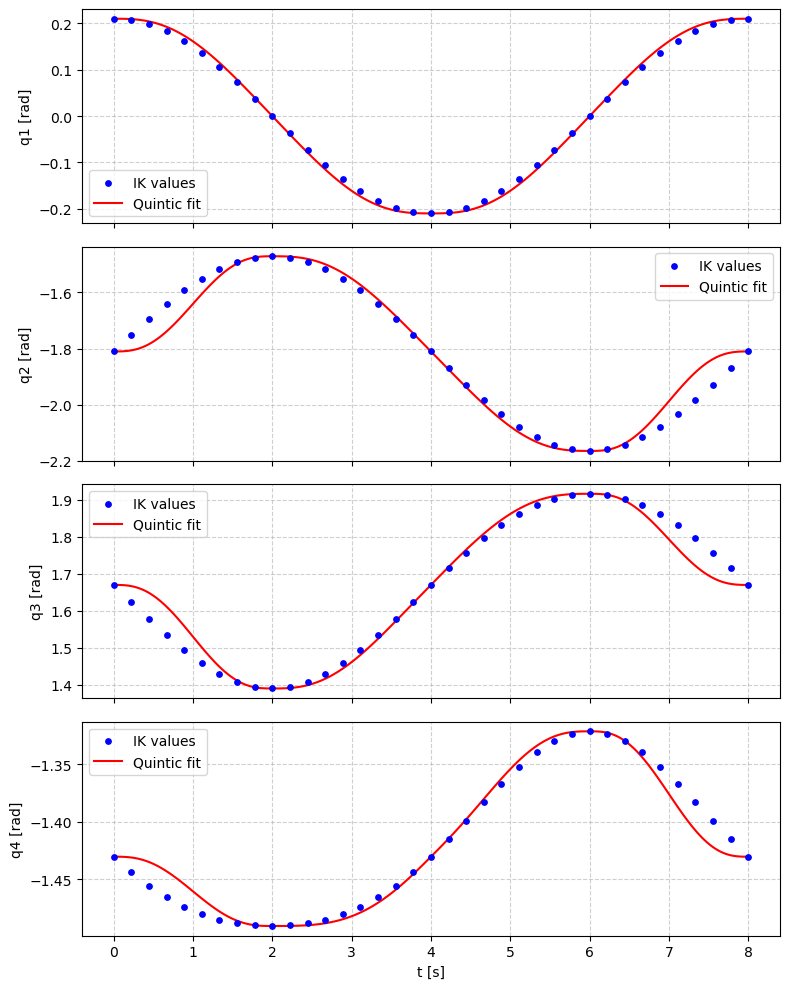

In [39]:
t_smooth = np.linspace(0, T_SEG, 100)
t_actual = np.linspace(0, 4*T_SEG, N + 1)
fig, axes = plt.subplots(4, 1, figsize=(8, 10), sharex=True)
for i, ax in enumerate(axes):
    ax.scatter(t_actual, Q[i], color="blue", s=15, label="IK values", zorder=5)
    for n, name in enumerate("ABCD"):
        ax.plot(t_smooth + n*T_SEG, np.polyval(coeffs[name][i], t_smooth),
                color="red", label="Quintic fit" if n == 0 else None)
    ax.set_ylabel(f"q{i+1} [rad]"); ax.grid(True, ls="--", alpha=0.6); ax.legend()
axes[-1].set_xlabel("t [s]")
plt.tight_layout(); plt.savefig("figures/fig_quintic_joints.png", dpi=200); plt.show()

## Problem 7 – Actual path and improvement

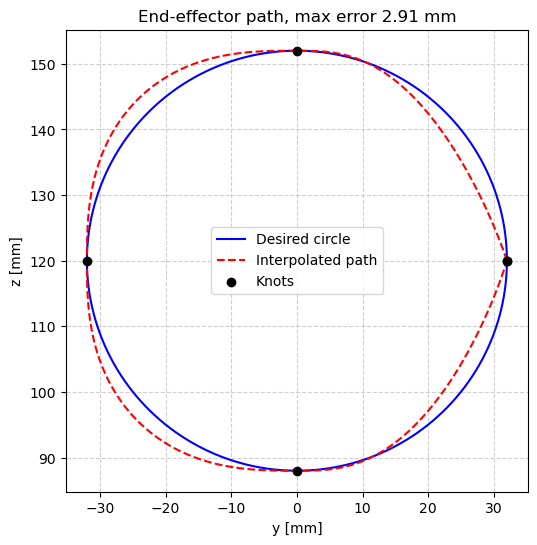

In [40]:
t = np.linspace(0, T_SEG, 200)
q_4seg = np.hstack([np.array([np.polyval(coeffs[n][i], t) for i in range(4)]) for n in "ABCD"])
path = np.array(f_pos(*q_4seg))
ang = np.linspace(0, 2*np.pi, 400)
radial_err = lambda p: np.hypot(p[0] - PC[0], np.hypot(p[1] - PC[1], p[2] - PC[2]) - R)
err = radial_err(path)

plt.figure(figsize=(6, 6))
plt.plot(PC[1] + R*np.cos(ang), PC[2] + R*np.sin(ang), "b-", label="Desired circle")
plt.plot(path[1], path[2], "r--", label="Interpolated path")
plt.scatter(x04[1, knots], x04[2, knots], c="k", zorder=5, label="Knots")
plt.gca().set_aspect("equal"); plt.grid(True, ls="--", alpha=0.6)
plt.xlabel("y [mm]"); plt.ylabel("z [mm]")
plt.title(f"End-effector path, max error {err.max():.2f} mm"); plt.legend(loc="center")
plt.savefig("figures/fig_path_4seg.png", dpi=200); plt.show()

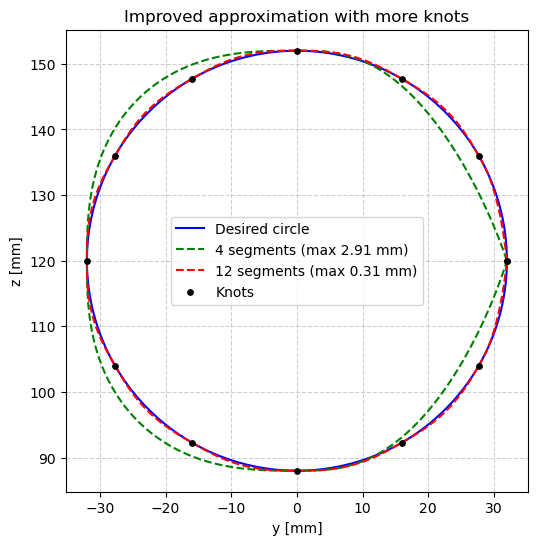

In [41]:
step = 3                                        # every 3rd IK sample is a knot -> 12 segments
idx = np.arange(0, 37, step); K = len(idx) - 1; T = 8.0 / K
speed = 2*np.pi*R/8                             # tangential speed of the circle [mm/s]

dq12 = []
for k in idx:
    v = np.zeros(3) if k in (0, 36) else speed*np.array([0, -np.sin(phis[k]), np.cos(phis[k])])
    J = np.array(f_ee(*Q[:, k]), dtype=float)
    dq12.append(np.linalg.solve(task_jac(J, Q[0, k]), np.append(v, 0)))
dq12 = np.array(dq12).T

t = np.linspace(0, T, 100)
q_12seg = np.hstack([np.array([np.polyval(solve_quintic_segment(Q[i, idx[s]], Q[i, idx[s+1]],
                                                               dq12[i, s], dq12[i, s+1], T=T), t)
                               for i in range(4)]) for s in range(K)])
path_new = np.array(f_pos(*q_12seg))
err_new = radial_err(path_new)

plt.figure(figsize=(6, 6))
plt.plot(PC[1] + R*np.cos(ang), PC[2] + R*np.sin(ang), "b-", label="Desired circle")
plt.plot(path[1], path[2], "g--", label=f"4 segments (max {err.max():.2f} mm)")
plt.plot(path_new[1], path_new[2], "r--", label=f"{K} segments (max {err_new.max():.2f} mm)")
plt.scatter(x04[1, idx], x04[2, idx], c="k", s=15, zorder=5, label="Knots")
plt.gca().set_aspect("equal"); plt.grid(True, ls="--", alpha=0.6)
plt.xlabel("y [mm]"); plt.ylabel("z [mm]")
plt.title("Improved approximation with more knots"); plt.legend(loc="center")
plt.savefig("figures/fig_path_12seg.png", dpi=200); plt.show()

## Problem 8 – Condition number

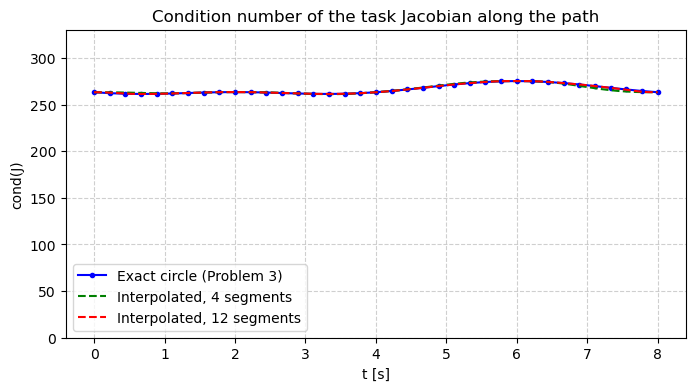

cond(J): exact 261.5-275.3, 4 seg 261.3-275.3, 12 seg 261.5-275.3
smallest singular value (exact circle): 0.689-0.803
q3 range along circle [rad]: 1.39 to 1.92


In [42]:
def cond_along(qs):
    return np.array([np.linalg.cond(task_jac(np.array(f_ee(*c), dtype=float), c[0])) for c in qs.T])
def smin_along(qs):
    return np.array([np.linalg.svd(task_jac(np.array(f_ee(*c), dtype=float), c[0]), compute_uv=False)[-1]
                     for c in qs.T])

c_exact, c_4, c_12 = cond_along(Q), cond_along(q_4seg), cond_along(q_12seg)
plt.figure(figsize=(8, 4))
plt.plot(phis/(2*np.pi)*8, c_exact, "bo-", ms=3, label="Exact circle (Problem 3)")
plt.plot(np.linspace(0, 8, q_4seg.shape[1]),  c_4,  "g--", label="Interpolated, 4 segments")
plt.plot(np.linspace(0, 8, q_12seg.shape[1]), c_12, "r--", label="Interpolated, 12 segments")
plt.ylim(0, 1.2*max(c_exact.max(), c_4.max(), c_12.max()))
plt.xlabel("t [s]"); plt.ylabel("cond(J)"); plt.grid(True, ls="--", alpha=0.6)
plt.title("Condition number of the task Jacobian along the path"); plt.legend()
plt.savefig("figures/fig_cond.png", dpi=200); plt.show()

print(f"cond(J): exact {c_exact.min():.1f}-{c_exact.max():.1f}, "
      f"4 seg {c_4.min():.1f}-{c_4.max():.1f}, 12 seg {c_12.min():.1f}-{c_12.max():.1f}")
print(f"smallest singular value (exact circle): {smin_along(Q).min():.3f}-{smin_along(Q).max():.3f}")
print(f"q3 range along circle [rad]: {Q[2].min():.2f} to {Q[2].max():.2f}")

## Problem 9 – Static joint torques (1 N downward at the tip)

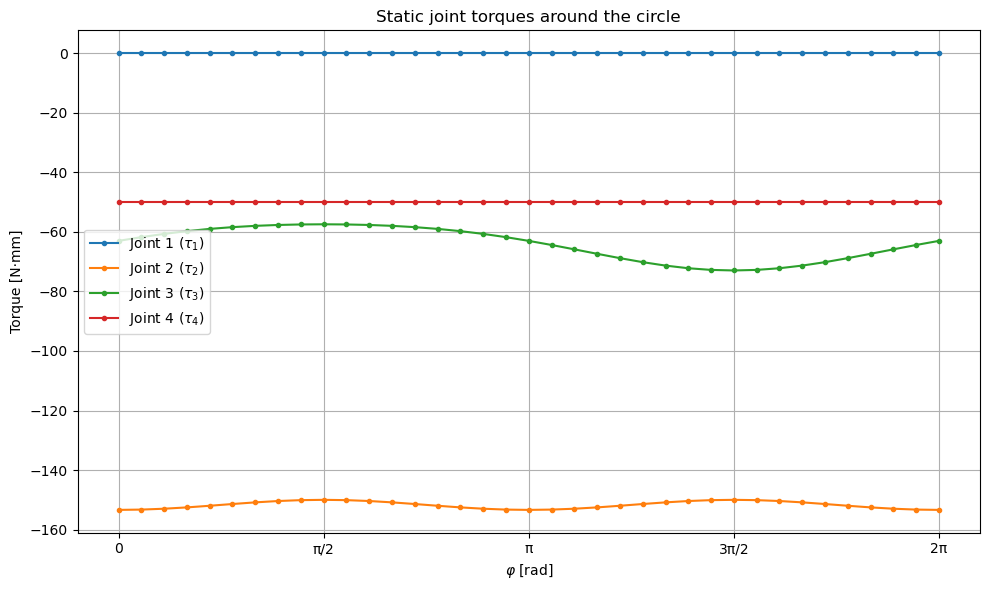

tau min/max per joint [N·mm]:
 [[   0.      0.  ]
 [-153.38 -150.  ]
 [ -72.98  -57.47]
 [ -50.    -50.  ]]


In [43]:
F = np.array([0, 0, -1, 0, 0, 0])                # N
tau = np.array([np.array(f_ee(*Q[:, j]), dtype=float).T @ F for j in range(N + 1)])   # N·mm

plt.figure(figsize=(10, 6))
for i in range(4):
    plt.plot(phis, tau[:, i], marker='o', ms=3, label=rf'Joint {i+1} ($\tau_{{{i+1}}}$)')
plt.xlabel(r'$\varphi$ [rad]'); plt.ylabel('Torque [N·mm]')
plt.xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi], ['0', 'π/2', 'π', '3π/2', '2π'])
plt.title('Static joint torques around the circle')
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig("figures/fig_torques.png", dpi=200); plt.show()
print("tau min/max per joint [N·mm]:\n", np.c_[tau.min(0), tau.max(0)].round(2))

## Problem 10 – Estimate of I0
`D̄1` is given in the CM frame, so no parallel-axis term is added. Link 1 is modelled as a box; **replace the dimensions with measured values**.

In [44]:
m1 = 0.060             # kg
a0, b0 = 0.040, 0.025  # m  (measure these! note.)
I0 = m1*(a0**2 + b0**2)/12
print(f"I0 = {I0:.3e} kg m^2")

I0 = 1.113e-05 kg m^2
